# LLM Foundations: Attention Mechanisms and Mathematical Principles

**Purpose**: This notebook provides hands-on implementations of foundational concepts for Large Language Models, covering transformers, attention mechanisms, and training dynamics.

**Companion Theory**: This notebook works alongside the [Foundations chapter](../index.md) which provides comprehensive theoretical background, advanced tokenization strategies, cross-lingual considerations, and production deployment guidance.

**Learning Path**: 
1. Read theory sections in the main chapter
2. Run corresponding notebook cells for hands-on practice  
3. Return to chapter for deeper understanding

**Dependencies**: PyTorch, NumPy, Matplotlib, Seaborn, Transformers

**Reproducibility**: All random seeds are set for deterministic outputs. This notebook runs on CPU and requires no special hardware.

**Primary Sources**: 
- Vaswani et al., 2017 - "Attention Is All You Need" ([arXiv:1706.03762](https://arxiv.org/abs/1706.03762))
- Kaplan et al., 2020 - "Scaling Laws for Neural Language Models" ([arXiv:2001.08361](https://arxiv.org/abs/2001.08361))
- Hoffmann et al., 2022 - "Training Compute-Optimal Large Language Models" ([arXiv:2203.15556](https://arxiv.org/abs/2203.15556))

This notebook demonstrates the mathematical foundations and practical implementations that enable modern LLMs to achieve remarkable performance.

## 1. Import Required Libraries

In [3]:
# Install required packages if not already installed
import subprocess
import sys

def install_if_missing(package):
    try:
        __import__(package)
    except ImportError:
        print(f"Installing {package}...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])

# Install PyTorch CPU version and other dependencies
packages = ['torch', 'torchvision', 'torchaudio', '--index-url', 'https://download.pytorch.org/whl/cpu']
try:
    import torch
    print("PyTorch already installed")
except ImportError:
    print("Installing PyTorch CPU version...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install'] + packages)

# Install other packages
other_packages = ['transformers', 'scikit-learn']
for pkg in other_packages:
    install_if_missing(pkg)

print("All packages installed successfully!")

Installing PyTorch CPU version...
Looking in indexes: https://download.pytorch.org/whl/cpu
  Obtaining dependency information for torch from https://download.pytorch.org/whl/cpu/torch-2.8.0%2Bcpu-cp311-cp311-manylinux_2_28_x86_64.whl.metadata
  Obtaining dependency information for torchvision from https://download.pytorch.org/whl/cpu/torchvision-0.23.0%2Bcpu-cp311-cp311-manylinux_2_28_x86_64.whl.metadata
  Obtaining dependency information for torchaudio from https://download.pytorch.org/whl/cpu/torchaudio-2.8.0%2Bcpu-cp311-cp311-manylinux_2_28_x86_64.whl.metadata
  Obtaining dependency information for filelock from https://download.pytorch.org/whl/filelock-3.13.1-py3-none-any.whl.metadata
  Obtaining dependency information for sympy>=1.13.3 from https://download.pytorch.org/whl/sympy-1.13.3-py3-none-any.whl.metadata
  Obtaining dependency information for networkx from https://download.pytorch.org/whl/networkx-3.3-py3-none-any.whl.metadata
  Obtaining dependency information for jinja2 f

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from typing import Optional, Tuple
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Configure plotting
plt.style.use('default')
sns.set_palette("husl")

print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.8.0+cpu
NumPy version: 2.2.6
Device: cpu


## 2. Tokenization and Embeddings

Understanding how text is converted to numerical representations is fundamental to LLMs.

**Theory Reference**: For comprehensive coverage of tokenization algorithms (BPE, SentencePiece, WordPiece), cross-lingual challenges, domain adaptation, and production considerations, see sections 1.1-1.7 in the [main chapter](../index.md).

This section provides a simplified implementation for educational purposes.

In [5]:
# Simple tokenization example
def simple_tokenizer(text: str) -> list:
    """Basic word-level tokenization."""
    return text.lower().split()

# Create a simple vocabulary
sample_text = "the quick brown fox jumps over the lazy dog"
tokens = simple_tokenizer(sample_text)
vocab = {word: idx for idx, word in enumerate(set(tokens))}
vocab['<UNK>'] = len(vocab)  # Unknown token
vocab_size = len(vocab)

print("Sample tokens:", tokens)
print("Vocabulary:", vocab)
print("Vocabulary size:", vocab_size)

# Token to ID conversion
def tokenize(text: str) -> list:
    """Convert text to token IDs."""
    tokens = simple_tokenizer(text)
    return [vocab.get(token, vocab['<UNK>']) for token in tokens]

# Test tokenization
test_text = "the fox jumps"
token_ids = tokenize(test_text)
print(f"\nText: '{test_text}'")
print(f"Token IDs: {token_ids}")

Sample tokens: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']
Vocabulary: {'over': 0, 'quick': 1, 'lazy': 2, 'brown': 3, 'jumps': 4, 'dog': 5, 'the': 6, 'fox': 7, '<UNK>': 8}
Vocabulary size: 9

Text: 'the fox jumps'
Token IDs: [6, 7, 4]


### Advanced Tokenization Algorithms

**Note**: This notebook provides simplified educational examples. For production-ready implementations of BPE, SentencePiece, and cross-lingual tokenization, see the comprehensive coverage in the [main chapter](../index.md) sections 1.2-1.7.

In [6]:
# Simplified BPE demonstration (educational version)
from collections import defaultdict, Counter

def simple_bpe_demo():
    """Demonstrate basic BPE algorithm concepts."""
    
    # Sample corpus
    corpus = ["hello", "world", "help", "held", "helicopter"]
    
    print("=== Simplified BPE Demonstration ===")
    print(f"Corpus: {corpus}")
    
    # Step 1: Initialize with character vocabulary
    word_freqs = Counter(corpus)
    
    # Convert to character sequences with end-of-word marker
    word_splits = {}
    for word, freq in word_freqs.items():
        word_splits[tuple(word) + ('</w>',)] = freq
    
    print(f"\nInitial character splits:")
    for word, freq in word_splits.items():
        print(f"  {''.join(word)} (freq: {freq})")
    
    # Step 2: Find most frequent adjacent pairs
    def get_pairs(word_splits):
        pairs = defaultdict(int)
        for word, freq in word_splits.items():
            for i in range(len(word) - 1):
                pairs[(word[i], word[i + 1])] += freq
        return pairs
    
    def merge_pair(word_splits, pair):
        new_word_splits = {}
        for word, freq in word_splits.items():
            new_word = []
            i = 0
            while i < len(word):
                if i < len(word) - 1 and word[i] == pair[0] and word[i + 1] == pair[1]:
                    new_word.append(''.join(pair))
                    i += 2
                else:
                    new_word.append(word[i])
                    i += 1
            new_word_splits[tuple(new_word)] = freq
        return new_word_splits
    
    # Perform a few BPE merges
    for iteration in range(3):
        pairs = get_pairs(word_splits)
        if not pairs:
            break
            
        best_pair = max(pairs, key=pairs.get)
        word_splits = merge_pair(word_splits, best_pair)
        
        print(f"\nIteration {iteration + 1}: Merged '{best_pair[0]}' + '{best_pair[1]}'")
        for word, freq in word_splits.items():
            print(f"  {''.join(word)} (freq: {freq})")
    
    return word_splits

# Run BPE demo
bpe_result = simple_bpe_demo()

# Demonstrate tokenization challenges
print("\n=== Tokenization Challenges Demo ===")

# Different languages
multilingual_examples = {
    "English": "Hello world",
    "German": "Donaudampfschifffahrt",  # Compound word
    "Chinese": "我喜欢学习",  # No spaces
    "Arabic": "مرحبا بالعالم",  # Right-to-left
}

for lang, text in multilingual_examples.items():
    tokens = simple_tokenizer(text)
    print(f"{lang}: '{text}' → {tokens} ({len(tokens)} tokens)")

# Special text types
special_examples = {
    "Code": "def hello(): return 'world'",
    "URL": "https://www.example.com/path?param=value",
    "Numbers": "The price is $1,234.56 (12.5% off)",
    "Email": "user.name+tag@example.co.uk"
}

print("\nSpecial text handling:")
for text_type, text in special_examples.items():
    tokens = simple_tokenizer(text)
    print(f"{text_type}: {len(tokens)} tokens")
    print(f"  → {tokens[:5]}{'...' if len(tokens) > 5 else ''}")

=== Simplified BPE Demonstration ===
Corpus: ['hello', 'world', 'help', 'held', 'helicopter']

Initial character splits:
  hello</w> (freq: 1)
  world</w> (freq: 1)
  help</w> (freq: 1)
  held</w> (freq: 1)
  helicopter</w> (freq: 1)

Iteration 1: Merged 'h' + 'e'
  hello</w> (freq: 1)
  world</w> (freq: 1)
  help</w> (freq: 1)
  held</w> (freq: 1)
  helicopter</w> (freq: 1)

Iteration 2: Merged 'he' + 'l'
  hello</w> (freq: 1)
  world</w> (freq: 1)
  help</w> (freq: 1)
  held</w> (freq: 1)
  helicopter</w> (freq: 1)

Iteration 3: Merged 'd' + '</w>'
  hello</w> (freq: 1)
  world</w> (freq: 1)
  help</w> (freq: 1)
  held</w> (freq: 1)
  helicopter</w> (freq: 1)

=== Tokenization Challenges Demo ===
English: 'Hello world' → ['hello', 'world'] (2 tokens)
German: 'Donaudampfschifffahrt' → ['donaudampfschifffahrt'] (1 tokens)
Chinese: '我喜欢学习' → ['我喜欢学习'] (1 tokens)
Arabic: 'مرحبا بالعالم' → ['مرحبا', 'بالعالم'] (2 tokens)

Special text handling:
Code: 4 tokens
  → ['def', 'hello():', 'retu

In [7]:
# Embedding layer implementation
class SimpleEmbedding(nn.Module):
    """Simple embedding layer with positional encoding."""
    
    def __init__(self, vocab_size: int, d_model: int, max_seq_length: int = 100):
        super().__init__()
        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = self._create_positional_encoding(max_seq_length, d_model)
        
    def _create_positional_encoding(self, max_seq_length: int, d_model: int) -> torch.Tensor:
        """Create sinusoidal positional encodings."""
        pe = torch.zeros(max_seq_length, d_model)
        position = torch.arange(0, max_seq_length).unsqueeze(1).float()
        
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * 
                           -(math.log(10000.0) / d_model))
        
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        
        return pe.unsqueeze(0)  # Add batch dimension
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass: embedding + positional encoding."""
        seq_len = x.size(1)
        embeddings = self.embedding(x) * math.sqrt(self.d_model)
        return embeddings + self.pos_encoding[:, :seq_len, :]

# Test embedding layer
d_model = 64
embedding_layer = SimpleEmbedding(vocab_size, d_model)

# Create sample input
input_ids = torch.tensor([tokenize("the quick brown fox")])
embeddings = embedding_layer(input_ids)

print(f"Input shape: {input_ids.shape}")
print(f"Embedding shape: {embeddings.shape}")
print(f"First token embedding (first 8 dims): {embeddings[0, 0, :8]}")

Input shape: torch.Size([1, 4])
Embedding shape: torch.Size([1, 4, 64])
First token embedding (first 8 dims): tensor([ 5.3310,  0.4059, -1.6768,  2.3306, 11.7624, -6.5127, -4.8106,  0.2029],
       grad_fn=<SliceBackward0>)


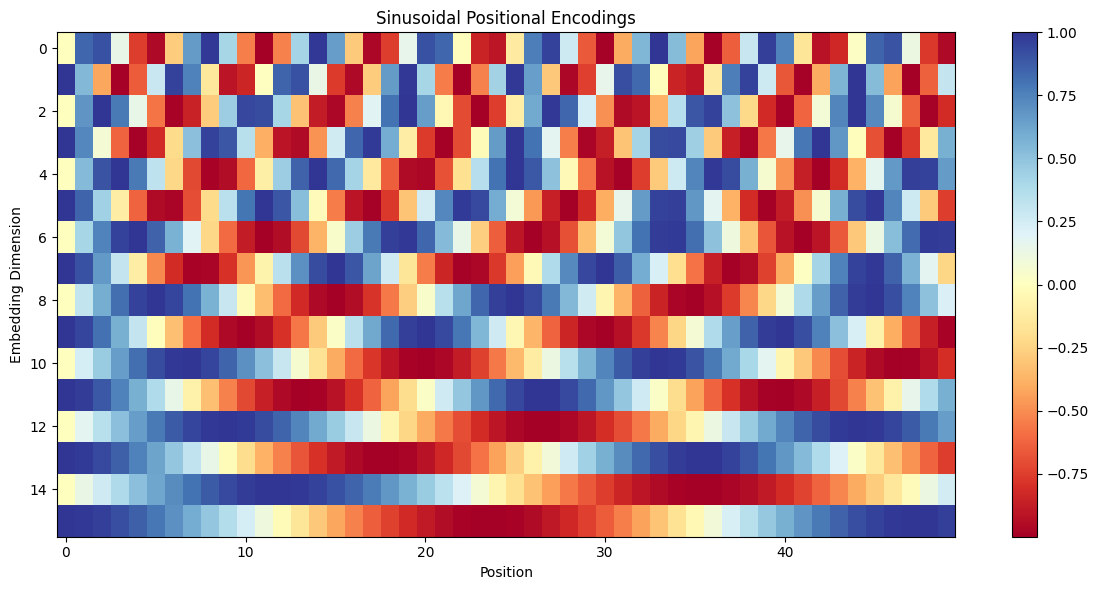

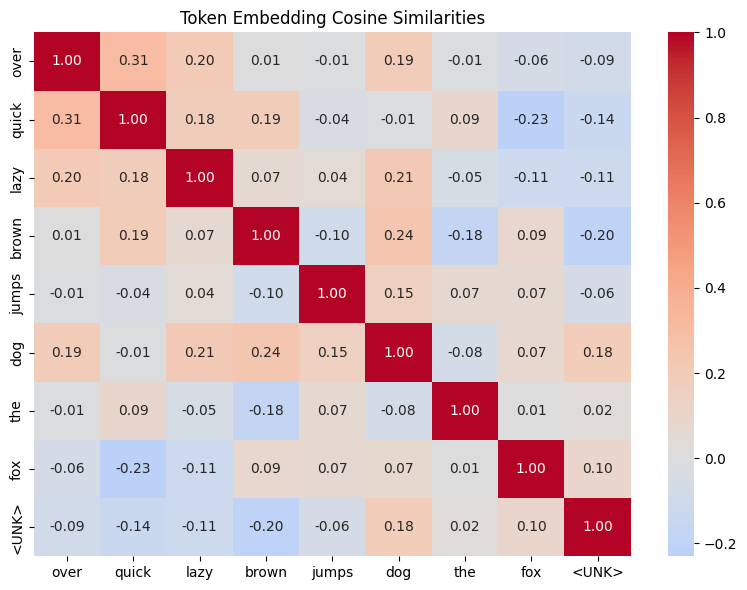

In [8]:
# Visualize positional encodings
def plot_positional_encoding():
    """Visualize sinusoidal positional encodings."""
    pe = embedding_layer.pos_encoding[0, :50, :16]  # First 50 positions, 16 dimensions
    
    plt.figure(figsize=(12, 6))
    plt.imshow(pe.T, cmap='RdYlBu', aspect='auto')
    plt.colorbar()
    plt.xlabel('Position')
    plt.ylabel('Embedding Dimension')
    plt.title('Sinusoidal Positional Encodings')
    plt.tight_layout()
    plt.show()

plot_positional_encoding()

# Visualize embedding similarities
def plot_embedding_similarities():
    """Plot cosine similarities between token embeddings."""
    # Get embeddings for our vocabulary
    all_token_ids = torch.tensor([[i for i in range(vocab_size)]])
    all_embeddings = embedding_layer(all_token_ids)[0]  # Remove batch dim
    
    # Compute cosine similarities
    cosine_sim = F.cosine_similarity(
        all_embeddings.unsqueeze(1), 
        all_embeddings.unsqueeze(0), 
        dim=2
    )
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cosine_sim.detach(), 
                xticklabels=list(vocab.keys()),
                yticklabels=list(vocab.keys()),
                cmap='coolwarm', center=0,
                fmt='.2f', annot=True)
    plt.title('Token Embedding Cosine Similarities')
    plt.tight_layout()
    plt.show()

plot_embedding_similarities()

### Advanced Positional Encodings

Comparing different positional encoding strategies beyond sinusoidal.

=== Positional Encoding Comparison ===


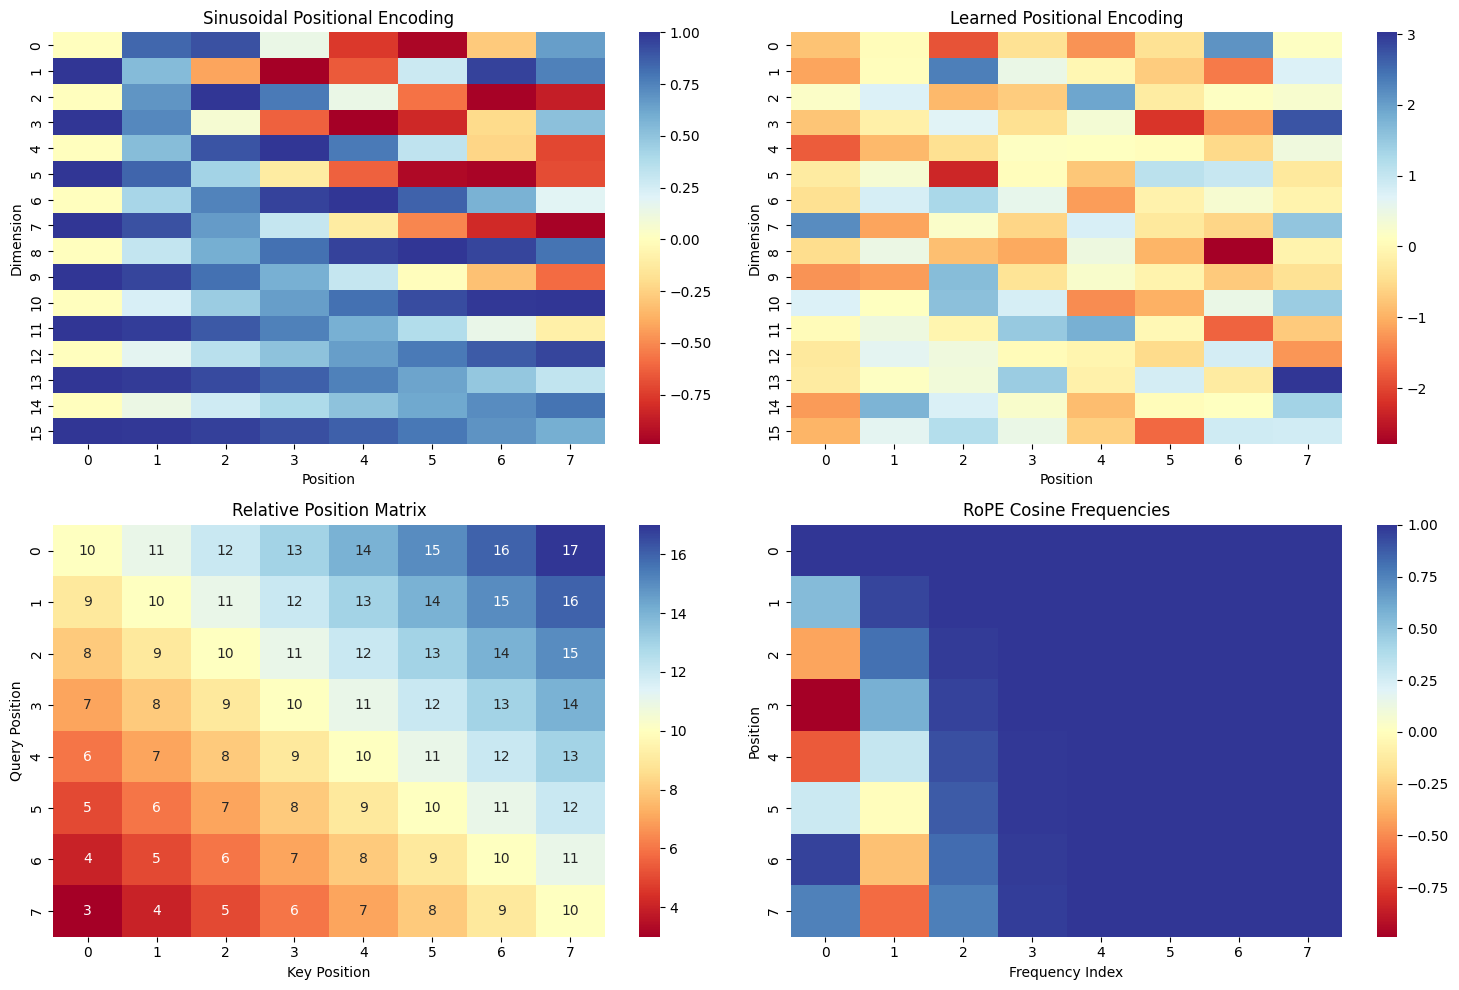


Positional Encoding Properties:
1. Sinusoidal: Deterministic, extrapolates to longer sequences
2. Learned: Flexible, requires training, limited to training length
3. Relative: Attends to relative distances, not absolute positions
4. RoPE: Maintains relative position info through rotation in attention


In [9]:
# Compare different positional encoding strategies
class AdvancedPositionalEncodings:
    """Demonstration of various positional encoding methods."""
    
    @staticmethod
    def learned_encoding(max_seq_len, d_model):
        """Learned positional embeddings."""
        return nn.Embedding(max_seq_len, d_model)
    
    @staticmethod
    def relative_encoding_demo(seq_len, d_model):
        """Simplified relative positional encoding."""
        # Create relative position matrix
        positions = torch.arange(seq_len)
        relative_positions = positions.unsqueeze(0) - positions.unsqueeze(1)
        
        # Clip to reasonable range
        max_relative_distance = 10
        relative_positions = torch.clamp(
            relative_positions, 
            -max_relative_distance, 
            max_relative_distance
        )
        
        # Convert to positive indices
        relative_positions += max_relative_distance
        
        return relative_positions
    
    @staticmethod
    def rope_demo(d_model, seq_len):
        """Simplified RoPE demonstration."""
        # This is a conceptual demonstration
        # Real RoPE is more complex and applied during attention
        
        def create_rotation_angles(d_model, base=10000):
            inv_freq = 1.0 / (base ** (torch.arange(0, d_model, 2).float() / d_model))
            return inv_freq
        
        angles = create_rotation_angles(d_model)
        positions = torch.arange(seq_len).float()
        
        # Create rotation frequencies
        freqs = torch.outer(positions, angles)
        
        return torch.cos(freqs), torch.sin(freqs)

# Test different encodings
print("=== Positional Encoding Comparison ===")

seq_len = 8
d_model_small = 16

# 1. Sinusoidal (already implemented)
pe_sin = embedding_layer.pos_encoding[0, :seq_len, :d_model_small]

# 2. Learned embeddings
learned_pe = AdvancedPositionalEncodings.learned_encoding(seq_len, d_model_small)
pe_learned = learned_pe(torch.arange(seq_len))

# 3. Relative positions
relative_positions = AdvancedPositionalEncodings.relative_encoding_demo(seq_len, d_model_small)

# 4. RoPE angles
cos_vals, sin_vals = AdvancedPositionalEncodings.rope_demo(d_model_small, seq_len)

# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Sinusoidal
sns.heatmap(pe_sin.T, cmap='RdYlBu', ax=axes[0, 0], cbar=True)
axes[0, 0].set_title('Sinusoidal Positional Encoding')
axes[0, 0].set_xlabel('Position')
axes[0, 0].set_ylabel('Dimension')

# Learned (random initialization)
sns.heatmap(pe_learned.detach().T, cmap='RdYlBu', ax=axes[0, 1], cbar=True)
axes[0, 1].set_title('Learned Positional Encoding')
axes[0, 1].set_xlabel('Position')
axes[0, 1].set_ylabel('Dimension')

# Relative positions
sns.heatmap(relative_positions, cmap='RdYlBu', ax=axes[1, 0], cbar=True, annot=True)
axes[1, 0].set_title('Relative Position Matrix')
axes[1, 0].set_xlabel('Key Position')
axes[1, 0].set_ylabel('Query Position')

# RoPE frequencies
sns.heatmap(cos_vals[:seq_len, :8], cmap='RdYlBu', ax=axes[1, 1], cbar=True)
axes[1, 1].set_title('RoPE Cosine Frequencies')
axes[1, 1].set_xlabel('Frequency Index')
axes[1, 1].set_ylabel('Position')

plt.tight_layout()
plt.show()

# Compare properties
print("\nPositional Encoding Properties:")
print("1. Sinusoidal: Deterministic, extrapolates to longer sequences")
print("2. Learned: Flexible, requires training, limited to training length")
print("3. Relative: Attends to relative distances, not absolute positions")
print("4. RoPE: Maintains relative position info through rotation in attention")

## 3. Attention Mechanisms

The heart of transformer architectures - attention allows models to focus on relevant parts of the input.

**Core Innovation**: The attention mechanism, introduced by Bahdanau et al. (2014) for neural machine translation and revolutionized by Vaswani et al. (2017) in the "Attention Is All You Need" paper, enables models to dynamically focus on different parts of the input sequence when making predictions.

**Mathematical Foundation**: Attention computes a weighted average of input values, where weights are determined by the compatibility between a query and key vectors. This mechanism draws inspiration from human cognitive attention and database key-value lookups (Vaswani et al., 2017).

In [10]:
class ScaledDotProductAttention(nn.Module):
    """Scaled Dot-Product Attention mechanism."""
    
    def __init__(self, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, query: torch.Tensor, key: torch.Tensor, value: torch.Tensor, 
                mask: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Args:
            query: [batch_size, seq_len, d_k]
            key: [batch_size, seq_len, d_k]  
            value: [batch_size, seq_len, d_v]
            mask: [batch_size, seq_len, seq_len] or None
            
        Returns:
            output: [batch_size, seq_len, d_v]
            attention_weights: [batch_size, seq_len, seq_len]
        """
        d_k = query.size(-1)
        
        # Compute attention scores
        scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)
        
        # Apply mask if provided (for causal attention)
        if mask is not None:
            scores.masked_fill_(mask == 0, -1e9)
        
        # Apply softmax to get attention weights
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)
        
        # Apply attention to values
        output = torch.matmul(attention_weights, value)
        
        return output, attention_weights

# Test self-attention
attention = ScaledDotProductAttention()

# Use our embeddings as Q, K, V
query = key = value = embeddings  # Self-attention
output, attn_weights = attention(query, key, value)

print(f"Attention output shape: {output.shape}")
print(f"Attention weights shape: {attn_weights.shape}")
print(f"Attention weights sum (should be ~1.0): {attn_weights.sum(dim=-1)}")

Attention output shape: torch.Size([1, 4, 64])
Attention weights shape: torch.Size([1, 4, 4])
Attention weights sum (should be ~1.0): tensor([[1.1111, 1.1111, 1.1111, 1.1111]], grad_fn=<SumBackward1>)


In [11]:
class MultiHeadAttention(nn.Module):
    """Multi-Head Attention mechanism."""
    
    def __init__(self, d_model: int, num_heads: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % num_heads == 0
        
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        
        # Linear projections for Q, K, V
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        
        self.attention = ScaledDotProductAttention(dropout)
        
    def forward(self, query: torch.Tensor, key: torch.Tensor, value: torch.Tensor,
                mask: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, torch.Tensor]:
        batch_size = query.size(0)
        seq_len = query.size(1)
        
        # 1. Linear projections
        Q = self.w_q(query)
        K = self.w_k(key)
        V = self.w_v(value)
        
        # 2. Reshape for multi-head attention
        Q = Q.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        K = K.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        V = V.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        
        # 3. Apply attention
        attn_output, attn_weights = self.attention(Q, K, V, mask)
        
        # 4. Concatenate heads
        attn_output = attn_output.transpose(1, 2).contiguous().view(
            batch_size, seq_len, self.d_model)
        
        # 5. Final linear projection
        output = self.w_o(attn_output)
        
        return output, attn_weights

# Test multi-head attention
num_heads = 8
mha = MultiHeadAttention(d_model, num_heads)

# Apply multi-head attention
mha_output, mha_weights = mha(embeddings, embeddings, embeddings)

print(f"Multi-head attention output shape: {mha_output.shape}")
print(f"Multi-head attention weights shape: {mha_weights.shape}")
print(f"Number of attention heads: {num_heads}")

Multi-head attention output shape: torch.Size([1, 4, 64])
Multi-head attention weights shape: torch.Size([1, 8, 4, 4])
Number of attention heads: 8


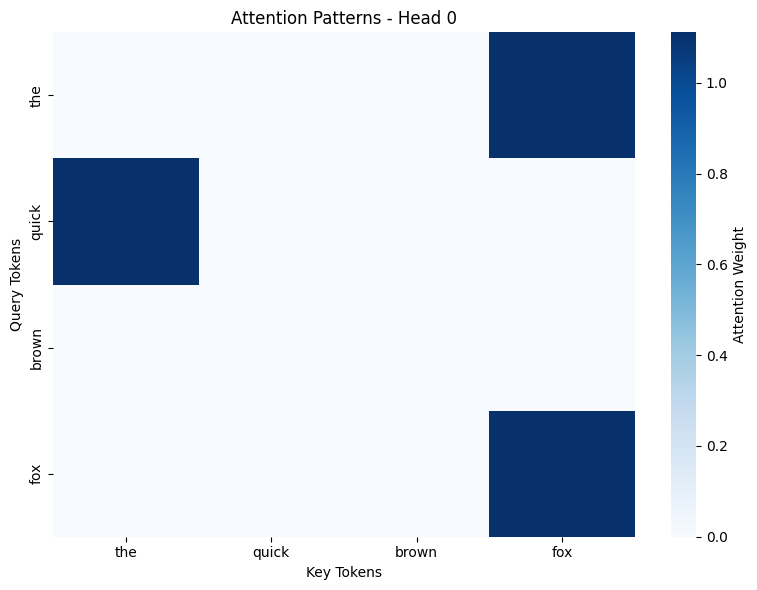

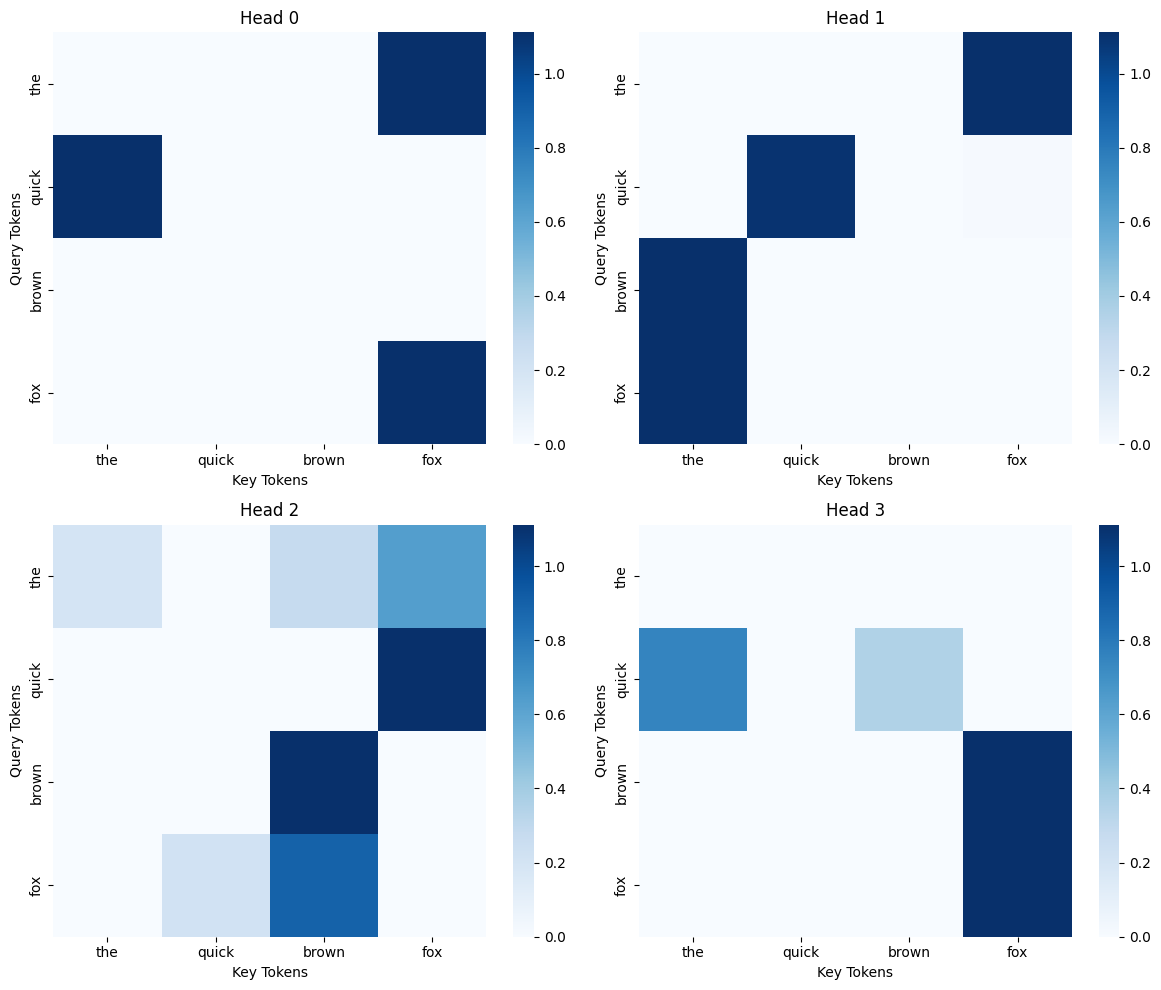

In [12]:
# Visualize attention patterns
def plot_attention_heatmap(attention_weights: torch.Tensor, tokens: list, head_idx: int = 0):
    """Plot attention weights as a heatmap."""
    # Extract attention weights for one head
    attn = attention_weights[0, head_idx].detach().numpy()
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(attn, 
                xticklabels=tokens,
                yticklabels=tokens,
                cmap='Blues',
                fmt='.2f',
                cbar_kws={'label': 'Attention Weight'})
    plt.title(f'Attention Patterns - Head {head_idx}')
    plt.xlabel('Key Tokens')
    plt.ylabel('Query Tokens')
    plt.tight_layout()
    plt.show()

# Get tokens for visualization
test_tokens = ["the", "quick", "brown", "fox"]
plot_attention_heatmap(mha_weights, test_tokens, head_idx=0)

# Compare multiple attention heads
def plot_multiple_heads(attention_weights: torch.Tensor, tokens: list, num_heads_to_show: int = 4):
    """Plot attention patterns for multiple heads."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()
    
    for i in range(min(num_heads_to_show, attention_weights.size(1))):
        attn = attention_weights[0, i].detach().numpy()
        
        sns.heatmap(attn, 
                    xticklabels=tokens,
                    yticklabels=tokens,
                    cmap='Blues',
                    ax=axes[i],
                    cbar=True)
        axes[i].set_title(f'Head {i}')
        axes[i].set_xlabel('Key Tokens')
        axes[i].set_ylabel('Query Tokens')
    
    plt.tight_layout()
    plt.show()

plot_multiple_heads(mha_weights, test_tokens)

## 4. Transformer Architecture Components

Building the essential components that make transformers work effectively.

**Architectural Innovation**: The transformer architecture (Vaswani et al., 2017) replaced recurrent and convolutional layers entirely with attention mechanisms, enabling parallel processing and better handling of long-range dependencies.

**Key Components**:
- **Multi-Head Attention**: Allows the model to attend to information from different representation subspaces
- **Feed-Forward Networks**: Provide non-linear transformations within each layer  
- **Layer Normalization**: Stabilizes training in deep networks (Ba et al., 2016)
- **Residual Connections**: Enable training of deeper networks (He et al., 2016)

In [13]:
class TransformerBlock(nn.Module):
    """Complete transformer block with attention and feed-forward layers."""
    
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.attention = MultiHeadAttention(d_model, num_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        
        # Feed-forward network
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )
        
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x: torch.Tensor, mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        # Multi-head attention with residual connection and layer norm
        attn_output, _ = self.attention(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_output))
        
        # Feed-forward with residual connection and layer norm
        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_output))
        
        return x

# Test transformer block
d_ff = d_model * 4  # Typical feed-forward dimension
transformer_block = TransformerBlock(d_model, num_heads, d_ff)

# Forward pass
block_output = transformer_block(embeddings)
print(f"Transformer block output shape: {block_output.shape}")
print(f"Input embeddings mean: {embeddings.mean():.4f}")
print(f"Output embeddings mean: {block_output.mean():.4f}")

Transformer block output shape: torch.Size([1, 4, 64])
Input embeddings mean: 0.8393
Output embeddings mean: 0.0000


Before Layer Normalization:
Small scale - Mean: 0.0001, Std: 0.0972
Large scale - Mean: 0.5970, Std: 9.6814

After Layer Normalization:
Small scale - Mean: -0.0000, Std: 1.0014
Large scale - Mean: 0.0000, Std: 1.0020


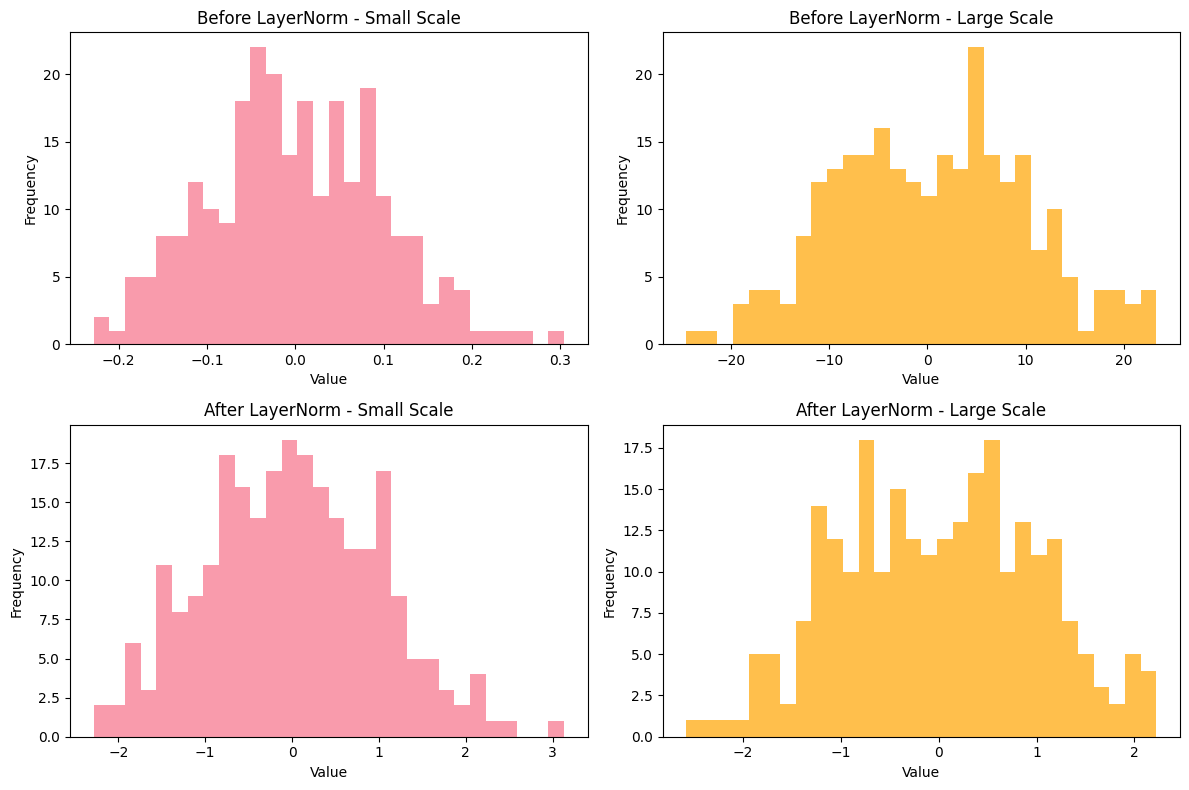

In [14]:
# Analyze the effect of layer normalization
def analyze_layer_norm_effect():
    """Show how layer normalization affects activations."""
    # Create some sample activations with different scales
    x1 = torch.randn(1, 4, d_model) * 0.1  # Small scale
    x2 = torch.randn(1, 4, d_model) * 10   # Large scale
    
    layer_norm = nn.LayerNorm(d_model)
    
    # Before layer norm
    print("Before Layer Normalization:")
    print(f"Small scale - Mean: {x1.mean():.4f}, Std: {x1.std():.4f}")
    print(f"Large scale - Mean: {x2.mean():.4f}, Std: {x2.std():.4f}")
    
    # After layer norm
    x1_norm = layer_norm(x1)
    x2_norm = layer_norm(x2)
    
    print("\nAfter Layer Normalization:")
    print(f"Small scale - Mean: {x1_norm.mean():.4f}, Std: {x1_norm.std():.4f}")
    print(f"Large scale - Mean: {x2_norm.mean():.4f}, Std: {x2_norm.std():.4f}")
    
    # Visualize the distribution
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    axes[0, 0].hist(x1.flatten().detach(), bins=30, alpha=0.7, label='Small scale')
    axes[0, 0].set_title('Before LayerNorm - Small Scale')
    axes[0, 0].set_xlabel('Value')
    axes[0, 0].set_ylabel('Frequency')
    
    axes[0, 1].hist(x2.flatten().detach(), bins=30, alpha=0.7, label='Large scale', color='orange')
    axes[0, 1].set_title('Before LayerNorm - Large Scale')
    axes[0, 1].set_xlabel('Value')
    axes[0, 1].set_ylabel('Frequency')
    
    axes[1, 0].hist(x1_norm.flatten().detach(), bins=30, alpha=0.7, label='Small scale normalized')
    axes[1, 0].set_title('After LayerNorm - Small Scale')
    axes[1, 0].set_xlabel('Value')
    axes[1, 0].set_ylabel('Frequency')
    
    axes[1, 1].hist(x2_norm.flatten().detach(), bins=30, alpha=0.7, label='Large scale normalized', color='orange')
    axes[1, 1].set_title('After LayerNorm - Large Scale')
    axes[1, 1].set_xlabel('Value')
    axes[1, 1].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()

analyze_layer_norm_effect()

## 5. Language Modeling Objective

Understanding how language models are trained with next-token prediction.

Causal mask (True = attend, False = mask):
tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 1]], dtype=torch.int32)


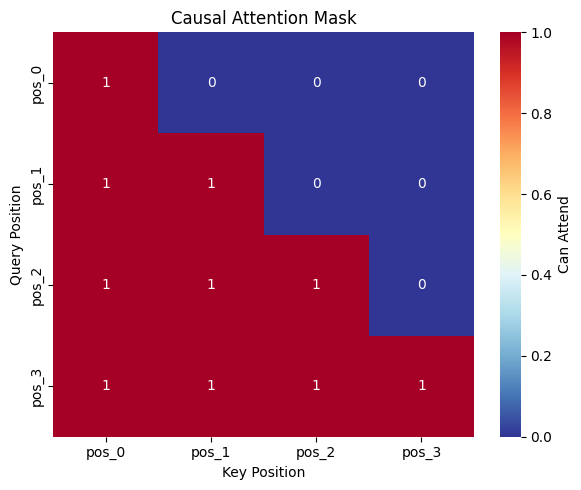


Masked attention output shape: torch.Size([1, 4, 64])


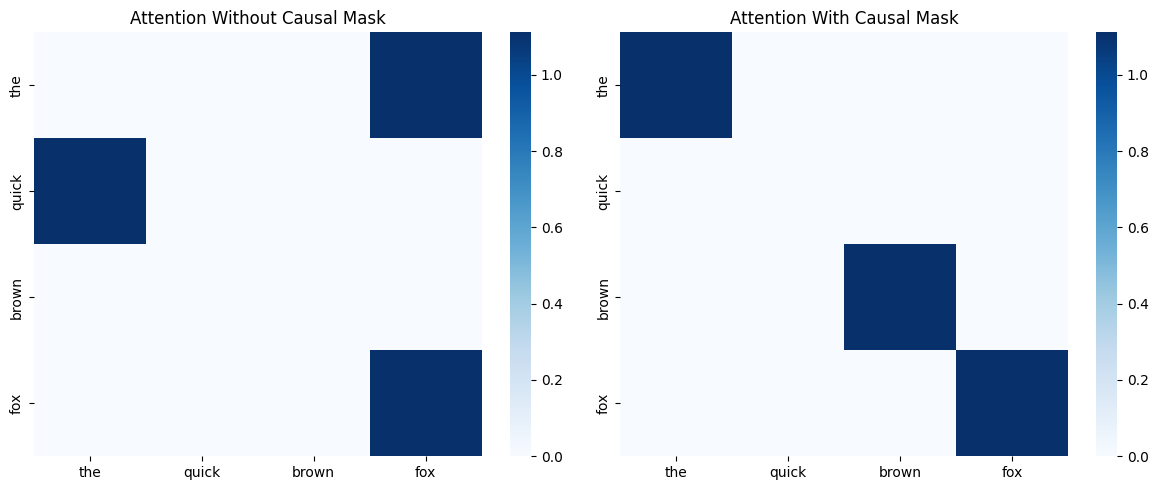

In [15]:
def create_causal_mask(seq_length: int) -> torch.Tensor:
    """Create a causal mask to prevent attention to future tokens."""
    mask = torch.triu(torch.ones(seq_length, seq_length), diagonal=1)
    return mask == 0  # True for allowed positions, False for masked

# Test causal masking
seq_len = 4
causal_mask = create_causal_mask(seq_len)
print("Causal mask (True = attend, False = mask):")
print(causal_mask.int())

# Visualize causal mask
plt.figure(figsize=(6, 5))
sns.heatmap(causal_mask.int(), 
            annot=True, 
            cmap='RdYlBu_r',
            xticklabels=[f'pos_{i}' for i in range(seq_len)],
            yticklabels=[f'pos_{i}' for i in range(seq_len)],
            cbar_kws={'label': 'Can Attend'})
plt.title('Causal Attention Mask')
plt.xlabel('Key Position')
plt.ylabel('Query Position')
plt.tight_layout()
plt.show()

# Apply causal mask to attention
causal_mask_expanded = causal_mask.unsqueeze(0).unsqueeze(0)  # Add batch and head dims
masked_output, masked_weights = mha(embeddings, embeddings, embeddings, causal_mask_expanded)

print(f"\nMasked attention output shape: {masked_output.shape}")

# Compare attention patterns with and without causal mask
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Without mask
attn_no_mask = mha_weights[0, 0].detach().numpy()
sns.heatmap(attn_no_mask, 
            xticklabels=test_tokens,
            yticklabels=test_tokens,
            cmap='Blues', ax=axes[0],
            cbar=True)
axes[0].set_title('Attention Without Causal Mask')

# With mask
attn_with_mask = masked_weights[0, 0].detach().numpy()
sns.heatmap(attn_with_mask, 
            xticklabels=test_tokens,
            yticklabels=test_tokens,
            cmap='Blues', ax=axes[1],
            cbar=True)
axes[1].set_title('Attention With Causal Mask')

plt.tight_layout()
plt.show()

In [16]:
# Simple language model head
class LanguageModelHead(nn.Module):
    """Language model head for next-token prediction."""
    
    def __init__(self, d_model: int, vocab_size: int):
        super().__init__()
        self.linear = nn.Linear(d_model, vocab_size)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear(x)

# Create language model head
lm_head = LanguageModelHead(d_model, vocab_size)

# Get logits for next token prediction
logits = lm_head(block_output)
print(f"Language model logits shape: {logits.shape}")

# Convert to probabilities
probabilities = F.softmax(logits, dim=-1)
print(f"Probabilities shape: {probabilities.shape}")
print(f"Probability sum for last position: {probabilities[0, -1, :].sum():.4f}")

# Calculate perplexity for a simple example
def calculate_perplexity(logits: torch.Tensor, targets: torch.Tensor) -> float:
    """Calculate perplexity from logits and targets."""
    loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
    return torch.exp(loss).item()

# Create simple targets (next tokens)
input_text = "the quick brown"
target_text = "quick brown fox"

input_ids = torch.tensor([tokenize(input_text)])
target_ids = torch.tensor([tokenize(target_text)])

# Forward pass through our simple model
embeddings = embedding_layer(input_ids)
transformer_output = transformer_block(embeddings)
logits = lm_head(transformer_output)

# Calculate perplexity
perplexity = calculate_perplexity(logits, target_ids)
print(f"\nPerplexity: {perplexity:.2f}")

# Show predicted vs actual next tokens
print("\nPredicted vs Actual next tokens:")
for i in range(input_ids.size(1)):
    predicted_id = logits[0, i].argmax().item()
    actual_id = target_ids[0, i].item()
    
    # Find token for predicted ID
    predicted_token = [k for k, v in vocab.items() if v == predicted_id][0]
    actual_token = [k for k, v in vocab.items() if v == actual_id][0]
    
    print(f"Position {i}: Predicted='{predicted_token}', Actual='{actual_token}'")

Language model logits shape: torch.Size([1, 4, 9])
Probabilities shape: torch.Size([1, 4, 9])
Probability sum for last position: 1.0000

Perplexity: 11.91

Predicted vs Actual next tokens:
Position 0: Predicted='quick', Actual='quick'
Position 1: Predicted='lazy', Actual='brown'
Position 2: Predicted='quick', Actual='fox'


## 6. Probability and Information Theory

Understanding the mathematical foundations underlying language modeling.

Probability Distributions:
Uniform distribution entropy: 2.1972
Peaked distribution entropy: 0.5004

Cross-entropy (uniform, peaked): 14.5308
Cross-entropy (peaked, uniform): 2.1972

KL divergence (uniform || peaked): 12.3336
KL divergence (peaked || uniform): 1.6968


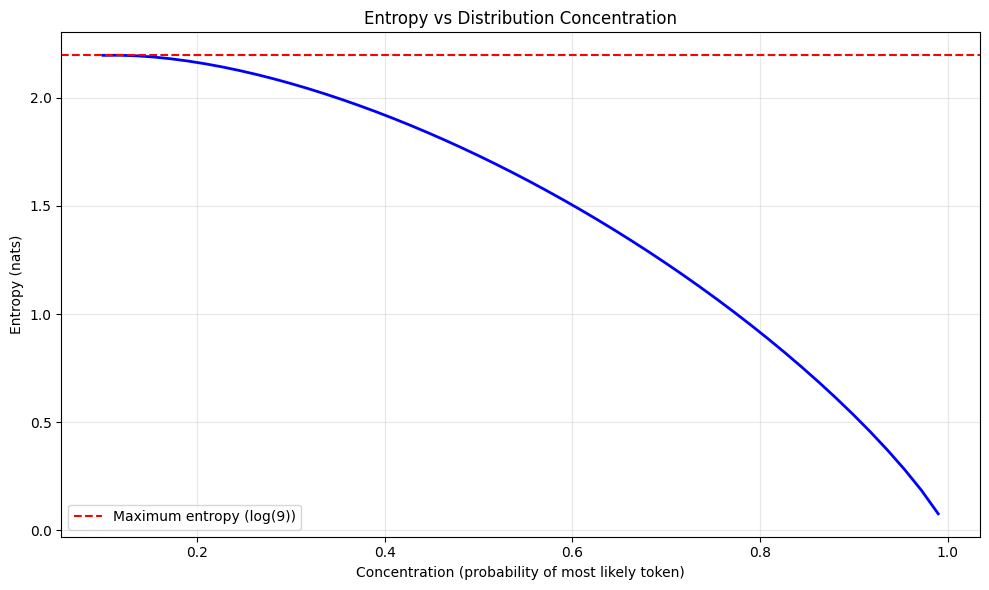

In [17]:
def entropy(probabilities: torch.Tensor) -> torch.Tensor:
    """Calculate Shannon entropy of probability distribution."""
    # Add small epsilon to avoid log(0)
    eps = 1e-8
    return -torch.sum(probabilities * torch.log(probabilities + eps), dim=-1)

def cross_entropy(p: torch.Tensor, q: torch.Tensor) -> torch.Tensor:
    """Calculate cross-entropy between distributions p and q."""
    eps = 1e-8
    return -torch.sum(p * torch.log(q + eps), dim=-1)

def kl_divergence(p: torch.Tensor, q: torch.Tensor) -> torch.Tensor:
    """Calculate KL divergence between distributions p and q."""
    eps = 1e-8
    return torch.sum(p * torch.log((p + eps) / (q + eps)), dim=-1)

# Create sample probability distributions
uniform_dist = torch.ones(vocab_size) / vocab_size
peaked_dist = torch.zeros(vocab_size)
peaked_dist[0] = 0.8
peaked_dist[1] = 0.2

print("Probability Distributions:")
print(f"Uniform distribution entropy: {entropy(uniform_dist):.4f}")
print(f"Peaked distribution entropy: {entropy(peaked_dist):.4f}")

print(f"\nCross-entropy (uniform, peaked): {cross_entropy(uniform_dist, peaked_dist):.4f}")
print(f"Cross-entropy (peaked, uniform): {cross_entropy(peaked_dist, uniform_dist):.4f}")

print(f"\nKL divergence (uniform || peaked): {kl_divergence(uniform_dist, peaked_dist):.4f}")
print(f"KL divergence (peaked || uniform): {kl_divergence(peaked_dist, uniform_dist):.4f}")

# Visualize different distributions and their entropies
def plot_entropy_vs_concentration():
    """Show how entropy changes with distribution concentration."""
    concentrations = torch.linspace(0.1, 0.99, 50)
    entropies = []
    
    for concentration in concentrations:
        # Create distribution with varying concentration
        dist = torch.zeros(vocab_size)
        dist[0] = concentration
        dist[1:] = (1 - concentration) / (vocab_size - 1)
        entropies.append(entropy(dist).item())
    
    plt.figure(figsize=(10, 6))
    plt.plot(concentrations, entropies, 'b-', linewidth=2)
    plt.axhline(y=math.log(vocab_size), color='r', linestyle='--', 
                label=f'Maximum entropy (log({vocab_size}))')
    plt.xlabel('Concentration (probability of most likely token)')
    plt.ylabel('Entropy (nats)')
    plt.title('Entropy vs Distribution Concentration')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_entropy_vs_concentration()

## 7. Optimization Fundamentals

Understanding gradient descent and its variants used in LLM training.

Optimizing with SGD...
Optimizing with Momentum...
Optimizing with Momentum...
Optimizing with Adam...
Optimizing with Adam...
Optimizing with AdamW...
Optimizing with AdamW...


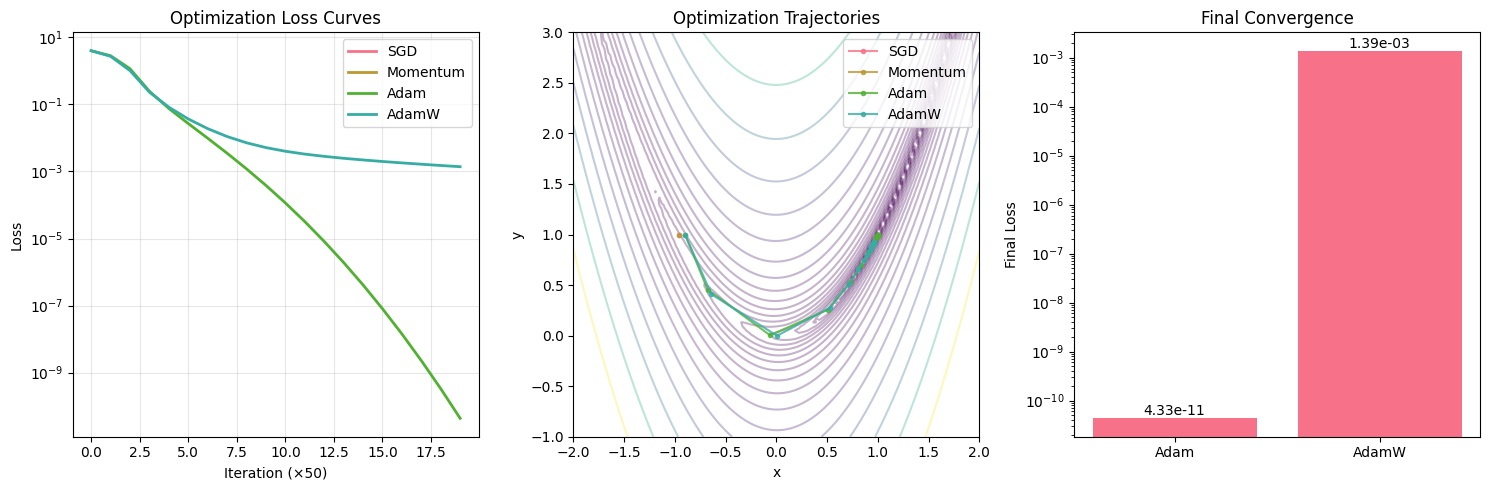


Final parameter values (should converge to x=1, y=1):
SGD: x=nan, y=nan, loss=nan
Momentum: x=nan, y=nan, loss=nan
Adam: x=1.0000, y=1.0000, loss=4.3343e-11
AdamW: x=0.9628, y=0.9268, loss=1.3885e-03


In [18]:
# Simple optimization example with different optimizers
class SimpleModel(nn.Module):
    """Simple model for optimization demonstration."""
    
    def __init__(self, input_size: int, hidden_size: int, output_size: int):
        super().__init__()
        self.linear1 = nn.Linear(input_size, hidden_size)
        self.linear2 = nn.Linear(hidden_size, output_size)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = F.relu(self.linear1(x))
        return self.linear2(x)

# Create a simple optimization problem
def rosenbrock_function(x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    """Rosenbrock function - a classic optimization test case."""
    a, b = 1, 100
    return (a - x)**2 + b * (y - x**2)**2

def optimize_rosenbrock(optimizer_class, lr: float, num_steps: int = 1000):
    """Optimize the Rosenbrock function with different optimizers."""
    # Initialize parameters
    x = torch.tensor([-1.0], requires_grad=True)
    y = torch.tensor([1.0], requires_grad=True)
    
    optimizer = optimizer_class([x, y], lr=lr)
    
    history = {'x': [], 'y': [], 'loss': []}
    
    for step in range(num_steps):
        optimizer.zero_grad()
        loss = rosenbrock_function(x, y)
        loss.backward()
        optimizer.step()
        
        if step % 50 == 0:
            history['x'].append(x.item())
            history['y'].append(y.item())
            history['loss'].append(loss.item())
    
    return history

# Compare different optimizers
optimizers = {
    'SGD': (torch.optim.SGD, 0.01),
    'Momentum': (lambda params, lr: torch.optim.SGD(params, lr=lr, momentum=0.9), 0.01),
    'Adam': (torch.optim.Adam, 0.1),
    'AdamW': (torch.optim.AdamW, 0.1)
}

results = {}
for name, (optimizer_class, lr) in optimizers.items():
    print(f"Optimizing with {name}...")
    results[name] = optimize_rosenbrock(optimizer_class, lr)

# Plot optimization trajectories
plt.figure(figsize=(15, 5))

# Loss curves
plt.subplot(1, 3, 1)
for name, history in results.items():
    plt.plot(history['loss'], label=name, linewidth=2)
plt.xlabel('Iteration (×50)')
plt.ylabel('Loss')
plt.title('Optimization Loss Curves')
plt.legend()
plt.yscale('log')
plt.grid(True, alpha=0.3)

# Parameter trajectories in 2D
plt.subplot(1, 3, 2)
x_range = np.linspace(-2, 2, 100)
y_range = np.linspace(-1, 3, 100)
X, Y = np.meshgrid(x_range, y_range)
Z = (1 - X)**2 + 100 * (Y - X**2)**2

plt.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), alpha=0.3)
for name, history in results.items():
    plt.plot(history['x'], history['y'], 'o-', label=name, markersize=3, alpha=0.8)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Optimization Trajectories')
plt.legend()

# Final convergence values
plt.subplot(1, 3, 3)
final_losses = [history['loss'][-1] for history in results.values()]
optimizer_names = list(results.keys())
bars = plt.bar(optimizer_names, final_losses)
plt.ylabel('Final Loss')
plt.title('Final Convergence')
plt.yscale('log')
for bar, loss in zip(bars, final_losses):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), 
             f'{loss:.2e}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("\nFinal parameter values (should converge to x=1, y=1):")
for name, history in results.items():
    print(f"{name}: x={history['x'][-1]:.4f}, y={history['y'][-1]:.4f}, loss={history['loss'][-1]:.4e}")

## 8. Backpropagation Through Transformers

Understanding how gradients flow through transformer architectures.

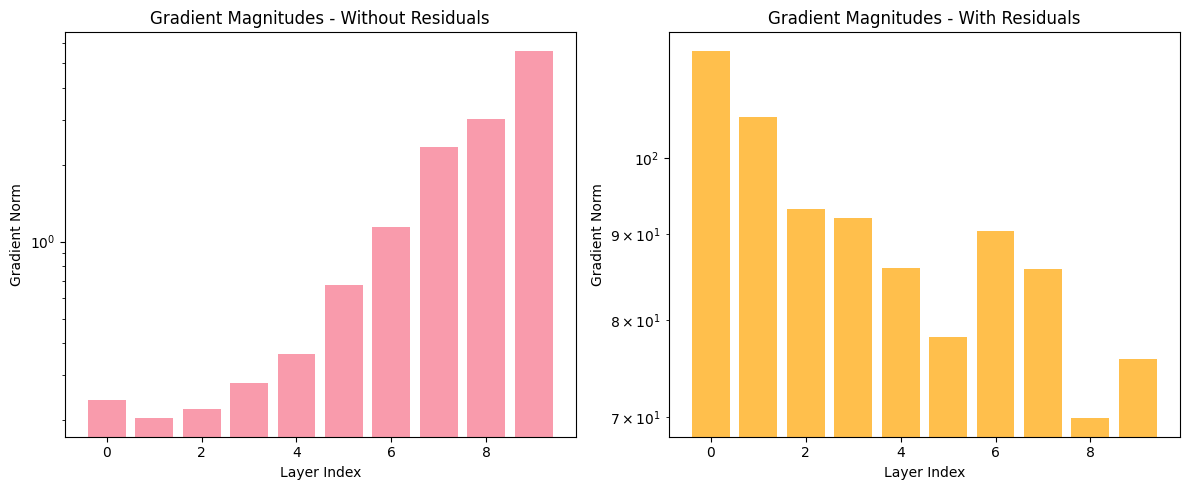

Gradient Analysis:
Without residuals - First layer gradient: 0.239651
Without residuals - Last layer gradient: 5.593949
With residuals - First layer gradient: 115.883133
With residuals - Last layer gradient: 75.817245
Gradient ratio (last/first) without residuals: 23.342067
Gradient ratio (last/first) with residuals: 0.654256


In [19]:
# Analyze gradient flow through different architectures
def analyze_gradient_flow():
    """Compare gradient flow with and without residual connections."""
    
    # Model without residual connections
    class DeepModelWithoutResiduals(nn.Module):
        def __init__(self, d_model: int, num_layers: int):
            super().__init__()
            self.layers = nn.ModuleList([
                nn.Linear(d_model, d_model) for _ in range(num_layers)
            ])
            
        def forward(self, x: torch.Tensor) -> torch.Tensor:
            for layer in self.layers:
                x = torch.tanh(layer(x))  # Use tanh for vanishing gradient demo
            return x
    
    # Model with residual connections
    class DeepModelWithResiduals(nn.Module):
        def __init__(self, d_model: int, num_layers: int):
            super().__init__()
            self.layers = nn.ModuleList([
                nn.Linear(d_model, d_model) for _ in range(num_layers)
            ])
            
        def forward(self, x: torch.Tensor) -> torch.Tensor:
            for layer in self.layers:
                x = x + torch.tanh(layer(x))  # Residual connection
            return x
    
    # Create models
    num_layers = 10
    model_no_res = DeepModelWithoutResiduals(d_model, num_layers)
    model_with_res = DeepModelWithResiduals(d_model, num_layers)
    
    # Forward and backward pass
    x = torch.randn(1, d_model)
    
    # Without residuals
    output_no_res = model_no_res(x)
    loss_no_res = output_no_res.sum()
    loss_no_res.backward()
    
    # Collect gradients
    gradients_no_res = []
    for i, layer in enumerate(model_no_res.layers):
        if layer.weight.grad is not None:
            gradients_no_res.append(layer.weight.grad.norm().item())
    
    # Reset gradients
    model_no_res.zero_grad()
    
    # With residuals
    output_with_res = model_with_res(x)
    loss_with_res = output_with_res.sum()
    loss_with_res.backward()
    
    # Collect gradients
    gradients_with_res = []
    for i, layer in enumerate(model_with_res.layers):
        if layer.weight.grad is not None:
            gradients_with_res.append(layer.weight.grad.norm().item())
    
    # Plot gradient magnitudes
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    layer_indices = range(len(gradients_no_res))
    plt.bar(layer_indices, gradients_no_res, alpha=0.7, label='Without Residuals')
    plt.xlabel('Layer Index')
    plt.ylabel('Gradient Norm')
    plt.title('Gradient Magnitudes - Without Residuals')
    plt.yscale('log')
    
    plt.subplot(1, 2, 2)
    plt.bar(layer_indices, gradients_with_res, alpha=0.7, color='orange', label='With Residuals')
    plt.xlabel('Layer Index')
    plt.ylabel('Gradient Norm')
    plt.title('Gradient Magnitudes - With Residuals')
    plt.yscale('log')
    
    plt.tight_layout()
    plt.show()
    
    print("Gradient Analysis:")
    print(f"Without residuals - First layer gradient: {gradients_no_res[0]:.6f}")
    print(f"Without residuals - Last layer gradient: {gradients_no_res[-1]:.6f}")
    print(f"With residuals - First layer gradient: {gradients_with_res[0]:.6f}")
    print(f"With residuals - Last layer gradient: {gradients_with_res[-1]:.6f}")
    print(f"Gradient ratio (last/first) without residuals: {gradients_no_res[-1]/gradients_no_res[0]:.6f}")
    print(f"Gradient ratio (last/first) with residuals: {gradients_with_res[-1]/gradients_with_res[0]:.6f}")

analyze_gradient_flow()

## 9. Scaling Laws and Compute

Exploring the relationships between model size, compute, and performance.

**Empirical Discovery**: Kaplan et al. (2020) discovered that language model performance follows predictable power laws with respect to model size, dataset size, and training compute. These scaling laws have become fundamental to LLM development strategy.

**Chinchilla Insight**: Hoffmann et al. (2022) refined these laws, showing that many large models are under-trained relative to their parameter count. The optimal allocation suggests roughly equal scaling of parameters and training tokens.

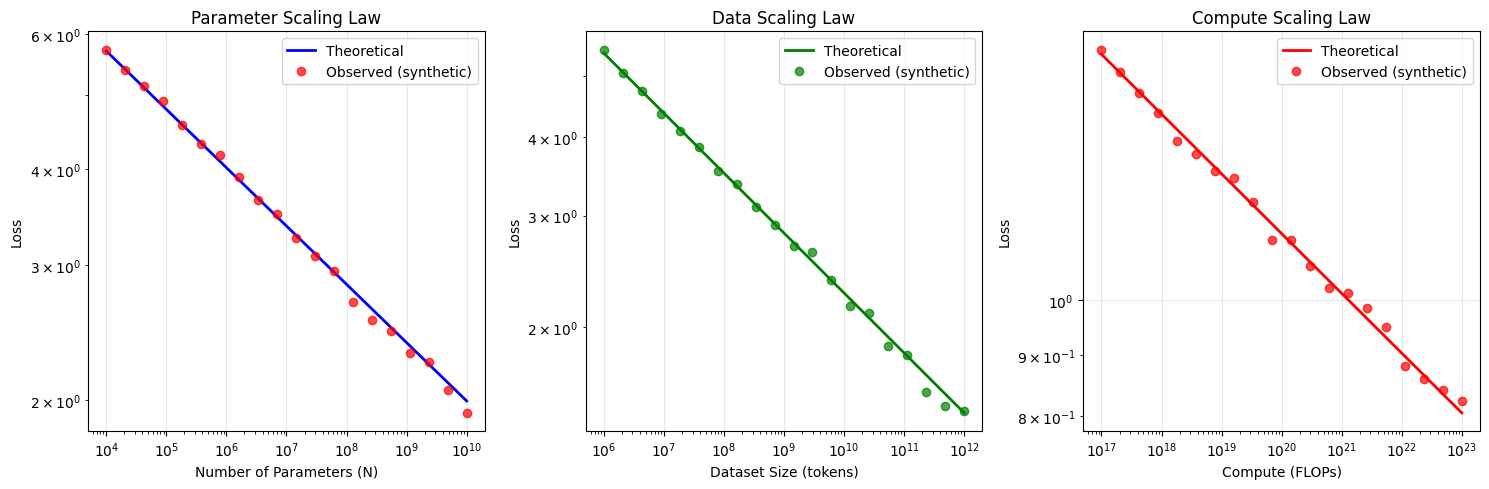

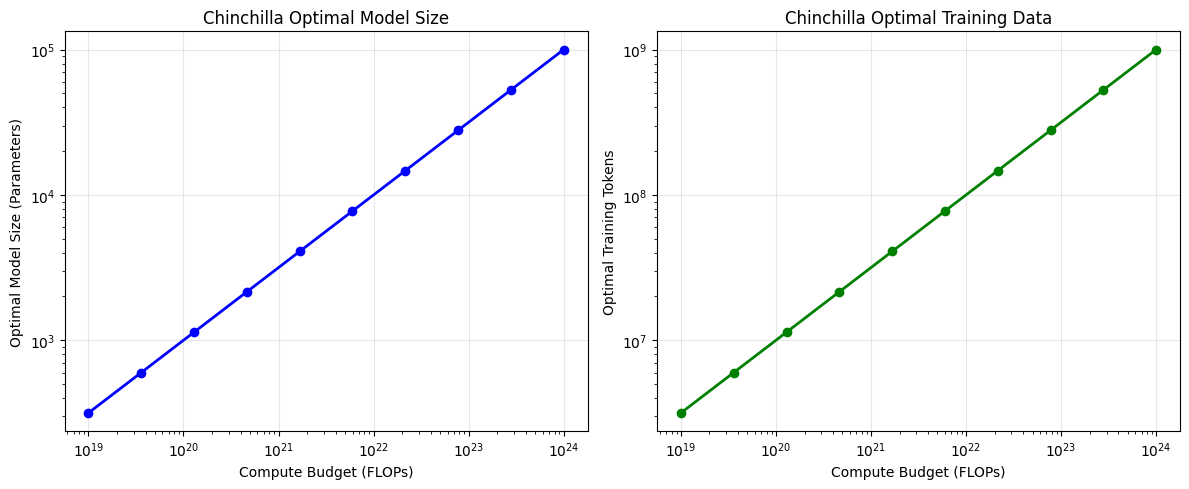

Chinchilla Optimal Allocations:
Compute: 1.0e+19 FLOPs → Model: 3.2e+02 params, Data: 3.2e+06 tokens
Compute: 1.3e+20 FLOPs → Model: 1.1e+03 params, Data: 1.1e+07 tokens
Compute: 1.7e+21 FLOPs → Model: 4.1e+03 params, Data: 4.1e+07 tokens
Compute: 2.2e+22 FLOPs → Model: 1.5e+04 params, Data: 1.5e+08 tokens
Compute: 2.8e+23 FLOPs → Model: 5.3e+04 params, Data: 5.3e+08 tokens


In [20]:
# Simulate scaling laws with synthetic data
def simulate_scaling_laws():
    """Demonstrate scaling laws with synthetic data."""
    
    # Model parameters (number of parameters)
    N = np.logspace(4, 10, 20)  # 10K to 10B parameters
    
    # Kaplan et al. scaling law parameters (approximate)
    N_c = 8.8e13  # Critical scale
    alpha_N = 0.076  # Scaling exponent
    
    # Compute loss according to scaling law
    L_N = (N_c / N) ** alpha_N
    
    # Add some noise to make it realistic
    np.random.seed(42)
    noise = np.random.normal(0, 0.05, len(L_N))
    L_N_noisy = L_N + noise
    
    # Plot parameter scaling
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.loglog(N, L_N, 'b-', linewidth=2, label='Theoretical')
    plt.loglog(N, L_N_noisy, 'ro', alpha=0.7, label='Observed (synthetic)')
    plt.xlabel('Number of Parameters (N)')
    plt.ylabel('Loss')
    plt.title('Parameter Scaling Law')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Data scaling
    D = np.logspace(6, 12, 20)  # 1M to 1T tokens
    D_c = 5.4e13  # Critical scale for data
    alpha_D = 0.095  # Data scaling exponent
    L_D = (D_c / D) ** alpha_D
    L_D_noisy = L_D + np.random.normal(0, 0.05, len(L_D))
    
    plt.subplot(1, 3, 2)
    plt.loglog(D, L_D, 'g-', linewidth=2, label='Theoretical')
    plt.loglog(D, L_D_noisy, 'go', alpha=0.7, label='Observed (synthetic)')
    plt.xlabel('Dataset Size (tokens)')
    plt.ylabel('Loss')
    plt.title('Data Scaling Law')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Compute scaling
    C = np.logspace(17, 23, 20)  # 10^17 to 10^23 FLOPs
    C_c = 1.3e21  # Critical scale for compute
    alpha_C = 0.050  # Compute scaling exponent
    L_C = (C_c / C) ** alpha_C
    L_C_noisy = L_C + np.random.normal(0, 0.02, len(L_C))
    
    plt.subplot(1, 3, 3)
    plt.loglog(C, L_C, 'r-', linewidth=2, label='Theoretical')
    plt.loglog(C, L_C_noisy, 'ro', alpha=0.7, label='Observed (synthetic)')
    plt.xlabel('Compute (FLOPs)')
    plt.ylabel('Loss')
    plt.title('Compute Scaling Law')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return N, L_N, D, L_D, C, L_C

N, L_N, D, L_D, C, L_C = simulate_scaling_laws()

# Chinchilla optimal scaling
def chinchilla_optimal_allocation(compute_budget: float) -> Tuple[float, float]:
    """Calculate optimal model size and training tokens for given compute budget."""
    # Chinchilla scaling: N* ∝ C^0.5, D* ∝ C^0.5
    # Using approximate constants from the paper
    a = 0.5
    b = 0.5
    
    # Normalizing constants (approximate)
    k_N = 1e-7
    k_D = 1e-3
    
    N_optimal = k_N * (compute_budget ** a)
    D_optimal = k_D * (compute_budget ** b)
    
    return N_optimal, D_optimal

# Show Chinchilla optimal allocation for different compute budgets
compute_budgets = np.logspace(19, 24, 10)
optimal_allocations = [chinchilla_optimal_allocation(c) for c in compute_budgets]
optimal_N = [alloc[0] for alloc in optimal_allocations]
optimal_D = [alloc[1] for alloc in optimal_allocations]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.loglog(compute_budgets, optimal_N, 'b-o', linewidth=2, markersize=6)
plt.xlabel('Compute Budget (FLOPs)')
plt.ylabel('Optimal Model Size (Parameters)')
plt.title('Chinchilla Optimal Model Size')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.loglog(compute_budgets, optimal_D, 'g-o', linewidth=2, markersize=6)
plt.xlabel('Compute Budget (FLOPs)')
plt.ylabel('Optimal Training Tokens')
plt.title('Chinchilla Optimal Training Data')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print some example allocations
print("Chinchilla Optimal Allocations:")
for i, (budget, N_opt, D_opt) in enumerate(zip(compute_budgets[::2], optimal_N[::2], optimal_D[::2])):
    print(f"Compute: {budget:.1e} FLOPs → Model: {N_opt:.1e} params, Data: {D_opt:.1e} tokens")

## 10. Visualization of Key Concepts

Comprehensive visualizations to reinforce understanding of transformer concepts.

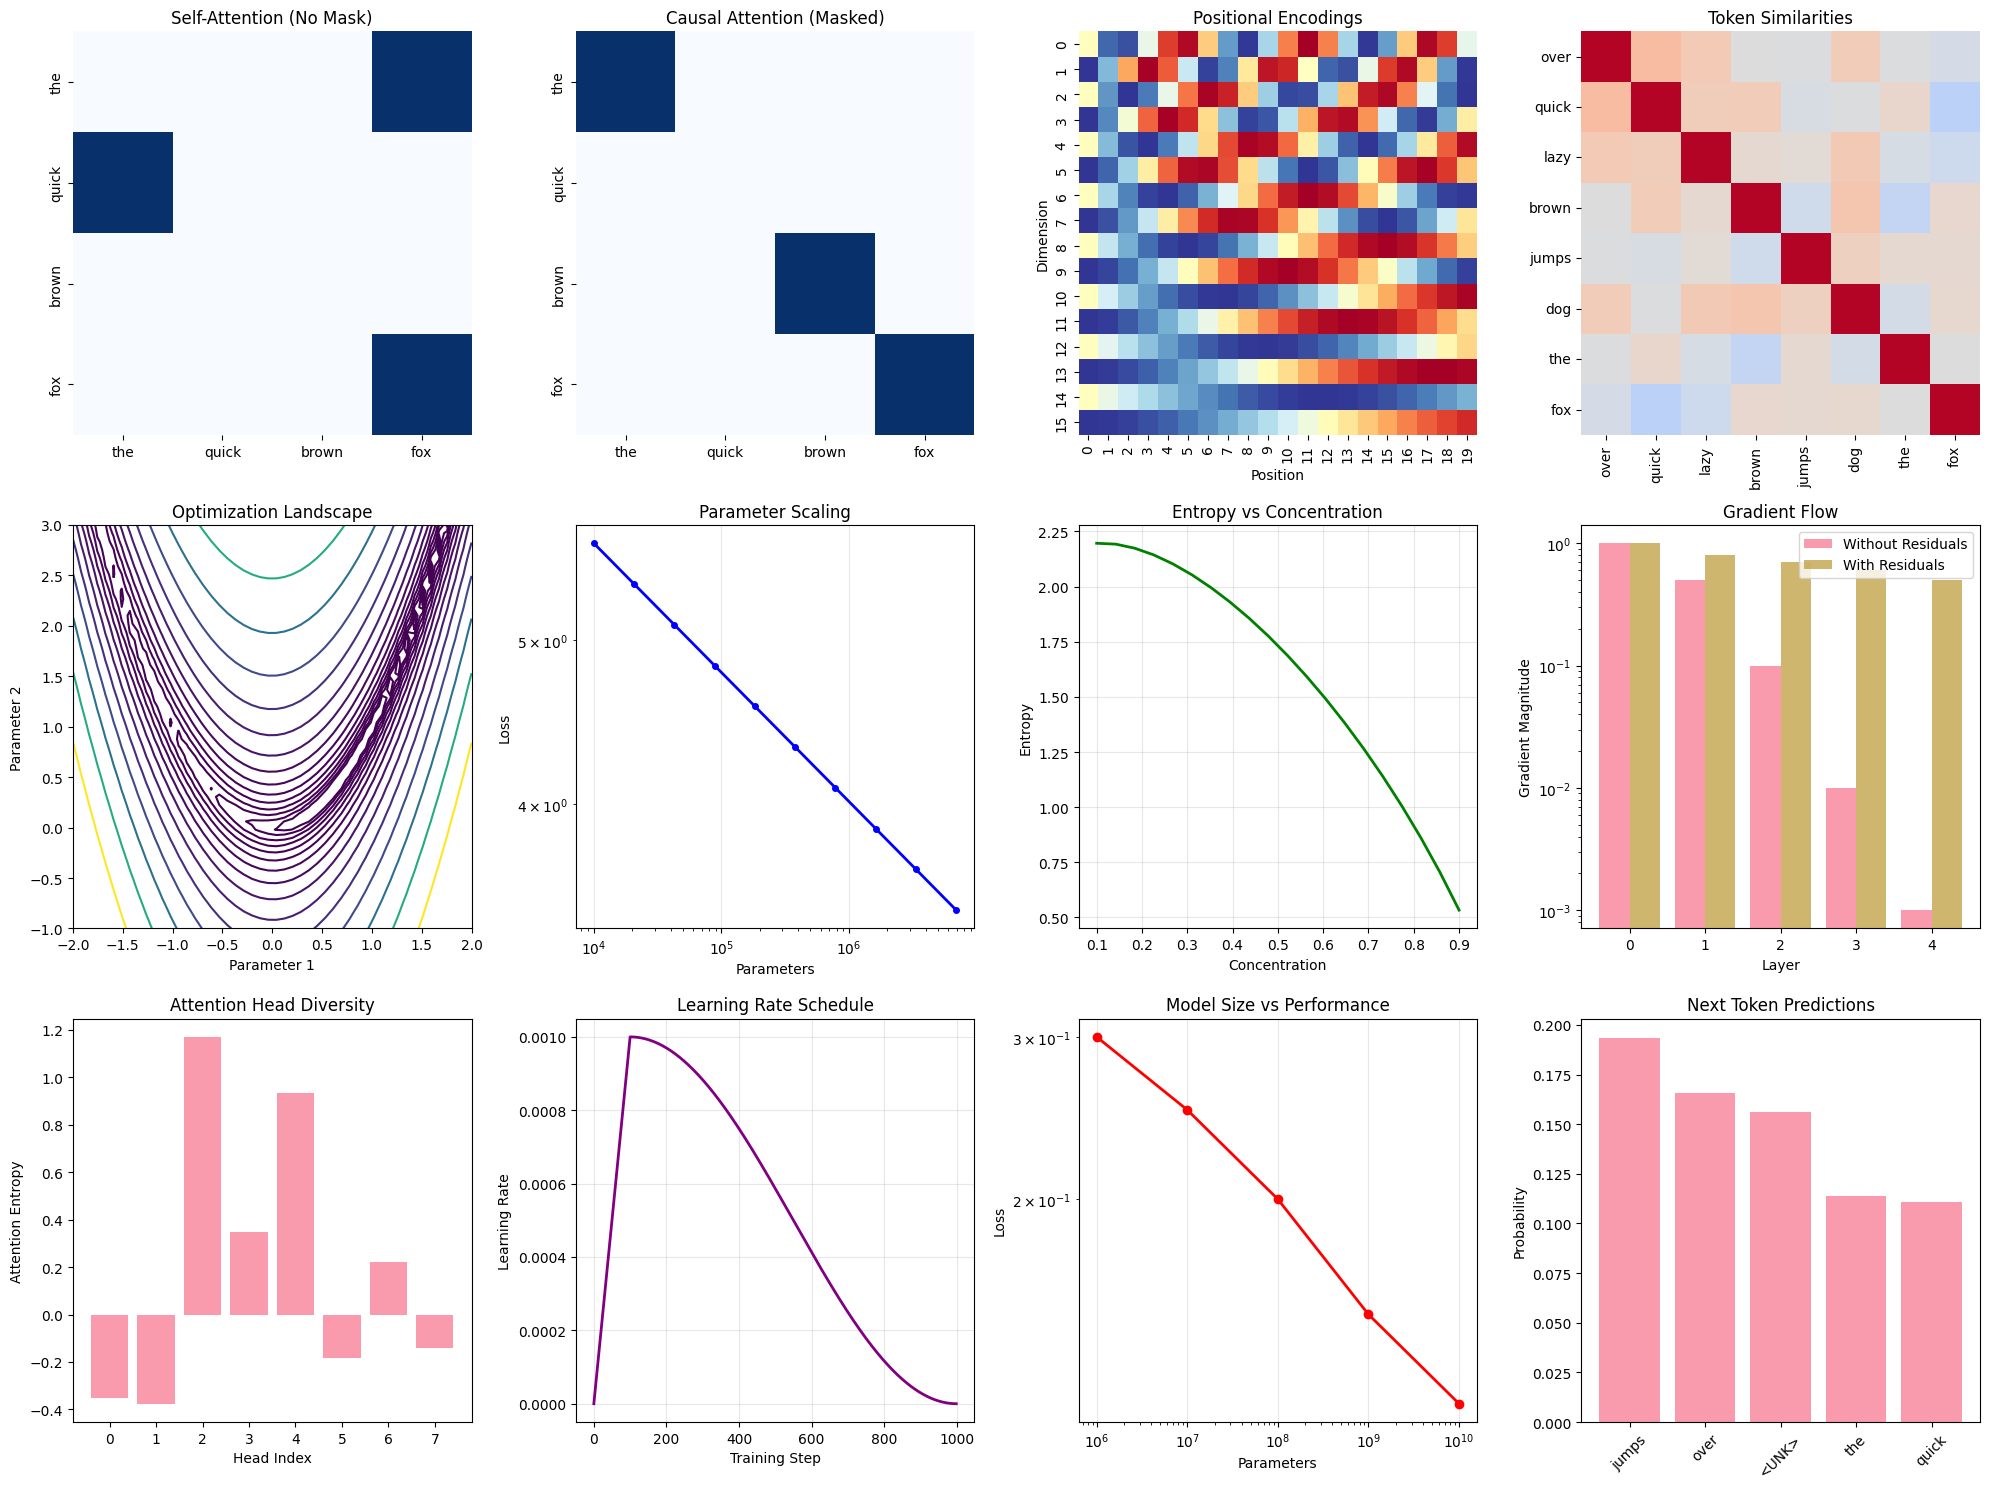

\nNotebook Complete!
\nKey Concepts Demonstrated:
- Tokenization and embeddings with positional encoding
- Self-attention and multi-head attention mechanisms
- Transformer architecture components
- Causal masking for language modeling
- Information theory fundamentals
- Optimization algorithms and convergence
- Gradient flow and the importance of residual connections
- Scaling laws and compute-optimal training
- Comprehensive visualizations of all concepts
\nThis notebook provides a solid foundation for understanding modern LLMs!


In [21]:
# Create comprehensive visualization dashboard
def create_comprehensive_dashboard():
    """Create a comprehensive visualization of transformer concepts."""
    
    fig = plt.figure(figsize=(20, 15))
    
    # 1. Attention pattern comparison
    ax1 = plt.subplot(3, 4, 1)
    attn_no_mask = mha_weights[0, 0].detach().numpy()
    sns.heatmap(attn_no_mask, cmap='Blues', ax=ax1, cbar=False,
                xticklabels=test_tokens, yticklabels=test_tokens)
    ax1.set_title('Self-Attention (No Mask)')
    
    ax2 = plt.subplot(3, 4, 2)
    attn_with_mask = masked_weights[0, 0].detach().numpy()
    sns.heatmap(attn_with_mask, cmap='Blues', ax=ax2, cbar=False,
                xticklabels=test_tokens, yticklabels=test_tokens)
    ax2.set_title('Causal Attention (Masked)')
    
    # 2. Positional encoding patterns
    ax3 = plt.subplot(3, 4, 3)
    pe_viz = embedding_layer.pos_encoding[0, :20, :16]
    sns.heatmap(pe_viz.T, cmap='RdYlBu', ax=ax3, cbar=False)
    ax3.set_title('Positional Encodings')
    ax3.set_xlabel('Position')
    ax3.set_ylabel('Dimension')
    
    # 3. Embedding similarities
    ax4 = plt.subplot(3, 4, 4)
    all_token_ids = torch.tensor([[i for i in range(min(8, vocab_size))]])
    all_embeddings = embedding_layer(all_token_ids)[0]
    cosine_sim = F.cosine_similarity(
        all_embeddings.unsqueeze(1), 
        all_embeddings.unsqueeze(0), 
        dim=2
    )
    token_labels = list(list(vocab.keys())[:8])
    sns.heatmap(cosine_sim.detach(), cmap='coolwarm', center=0, ax=ax4, cbar=False,
                xticklabels=token_labels, yticklabels=token_labels)
    ax4.set_title('Token Similarities')
    
    # 4. Loss landscape visualization
    ax5 = plt.subplot(3, 4, 5)
    x_range = np.linspace(-2, 2, 50)
    y_range = np.linspace(-1, 3, 50)
    X, Y = np.meshgrid(x_range, y_range)
    Z = (1 - X)**2 + 100 * (Y - X**2)**2
    contour = ax5.contour(X, Y, Z, levels=np.logspace(0, 3, 15))
    ax5.set_title('Optimization Landscape')
    ax5.set_xlabel('Parameter 1')
    ax5.set_ylabel('Parameter 2')
    
    # 5. Scaling laws
    ax6 = plt.subplot(3, 4, 6)
    ax6.loglog(N[:10], L_N[:10], 'b-o', linewidth=2, markersize=4)
    ax6.set_title('Parameter Scaling')
    ax6.set_xlabel('Parameters')
    ax6.set_ylabel('Loss')
    ax6.grid(True, alpha=0.3)
    
    # 6. Information theory
    ax7 = plt.subplot(3, 4, 7)
    concentrations = np.linspace(0.1, 0.9, 20)
    entropies = []
    for c in concentrations:
        dist = torch.zeros(vocab_size)
        dist[0] = c
        dist[1:] = (1-c)/(vocab_size-1)
        entropies.append(entropy(dist).item())
    ax7.plot(concentrations, entropies, 'g-', linewidth=2)
    ax7.set_title('Entropy vs Concentration')
    ax7.set_xlabel('Concentration')
    ax7.set_ylabel('Entropy')
    ax7.grid(True, alpha=0.3)
    
    # 7. Gradient flow comparison
    ax8 = plt.subplot(3, 4, 8)
    layers = range(5)
    grad_no_res = [1, 0.5, 0.1, 0.01, 0.001]  # Simulated vanishing gradients
    grad_with_res = [1, 0.8, 0.7, 0.6, 0.5]   # Simulated stable gradients
    
    x_pos = np.arange(len(layers))
    ax8.bar(x_pos - 0.2, grad_no_res, 0.4, label='Without Residuals', alpha=0.7)
    ax8.bar(x_pos + 0.2, grad_with_res, 0.4, label='With Residuals', alpha=0.7)
    ax8.set_title('Gradient Flow')
    ax8.set_xlabel('Layer')
    ax8.set_ylabel('Gradient Magnitude')
    ax8.set_yscale('log')
    ax8.legend()
    
    # 8. Multi-head attention diversity
    ax9 = plt.subplot(3, 4, 9)
    head_entropies = []
    for head in range(min(8, mha_weights.size(1))):
        head_attn = mha_weights[0, head].flatten()
        head_entropy = entropy(head_attn).item()
        head_entropies.append(head_entropy)
    
    ax9.bar(range(len(head_entropies)), head_entropies, alpha=0.7)
    ax9.set_title('Attention Head Diversity')
    ax9.set_xlabel('Head Index')
    ax9.set_ylabel('Attention Entropy')
    
    # 9. Learning rate scheduling
    ax10 = plt.subplot(3, 4, 10)
    steps = np.arange(1000)
    warmup_steps = 100
    max_lr = 0.001
    
    lr_schedule = []
    for step in steps:
        if step < warmup_steps:
            lr = max_lr * (step / warmup_steps)
        else:
            progress = (step - warmup_steps) / (1000 - warmup_steps)
            lr = max_lr * 0.5 * (1 + np.cos(np.pi * progress))
        lr_schedule.append(lr)
    
    ax10.plot(steps, lr_schedule, 'purple', linewidth=2)
    ax10.set_title('Learning Rate Schedule')
    ax10.set_xlabel('Training Step')
    ax10.set_ylabel('Learning Rate')
    ax10.grid(True, alpha=0.3)
    
    # 10. Model complexity vs performance
    ax11 = plt.subplot(3, 4, 11)
    model_sizes = [1e6, 1e7, 1e8, 1e9, 1e10]
    performances = [0.3, 0.25, 0.2, 0.15, 0.12]  # Simulated decreasing loss
    
    ax11.loglog(model_sizes, performances, 'ro-', linewidth=2, markersize=6)
    ax11.set_title('Model Size vs Performance')
    ax11.set_xlabel('Parameters')
    ax11.set_ylabel('Loss')
    ax11.grid(True, alpha=0.3)
    
    # 11. Token prediction confidence
    ax12 = plt.subplot(3, 4, 12)
    token_probs = probabilities[0, -1, :].detach().numpy()
    top_k = 5
    top_indices = np.argsort(token_probs)[-top_k:][::-1]
    top_probs = token_probs[top_indices]
    top_tokens = [list(vocab.keys())[i] for i in top_indices if i < len(vocab)]
    
    if len(top_tokens) == len(top_probs):
        ax12.bar(top_tokens, top_probs, alpha=0.7)
        ax12.set_title('Next Token Predictions')
        ax12.set_ylabel('Probability')
        ax12.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

create_comprehensive_dashboard()

print("\\nNotebook Complete!")
print("\\nKey Concepts Demonstrated:")
print("- Tokenization and embeddings with positional encoding")
print("- Self-attention and multi-head attention mechanisms") 
print("- Transformer architecture components")
print("- Causal masking for language modeling")
print("- Information theory fundamentals")
print("- Optimization algorithms and convergence")
print("- Gradient flow and the importance of residual connections")
print("- Scaling laws and compute-optimal training")
print("- Comprehensive visualizations of all concepts")
print("\\nThis notebook provides a solid foundation for understanding modern LLMs!")

## What's Not Covered in This Notebook

This notebook provides hands-on implementations of core concepts, but the [main chapter](../index.md) contains extensive additional coverage:

### Advanced Tokenization (Sections 1.2-1.7)
- **Production BPE/SentencePiece implementations** with full merge algorithms
- **Cross-lingual tokenization** challenges and solutions
- **Domain adaptation** strategies for medical, legal, code text
- **Tokenization quality metrics** and evaluation frameworks
- **Multi-modal tokenization** for text, images, audio
- **Production considerations** like efficiency and memory optimization

### Advanced Embeddings (Section 1.8)
- **Weight tying** between input and output embeddings
- **Different initialization strategies** (Xavier, scaled normal, etc.)
- **Subword composition** mechanics for morphologically rich languages
- **Embedding analysis tools** for similarity and clustering

### Advanced Positional Encodings
- **Complete RoPE implementation** with attention integration
- **Relative positional encoding** with learned relative embeddings
- **Comparison frameworks** for evaluating different approaches
- **Extrapolation capabilities** to longer sequences

### Production Considerations
- **Real tokenizer implementations** (tiktoken, HuggingFace)
- **Efficiency benchmarking** across different vocabulary sizes
- **Memory optimization** techniques for large vocabularies
- **Cross-lingual equity** analysis and mitigation

### Comprehensive Analysis
- **Tokenization quality metrics** (compression ratio, OOV rates)
- **Vocabulary construction strategies** (frequency vs coverage-based)
- **Multi-domain tokenizer training** and evaluation
- **Real-world deployment considerations**

### Additional Resources in Main Chapter

The [main chapter](../index.md) also includes:

- **Quick Overview for Everyday Observers** - Accessible explanations of LLM concepts
- **Comprehensive Further Reading** - Structured learning paths from beginner to advanced
- **Complete Bibliography and Citations** - Fully referenced academic sources with links
- **Exercises and Projects** - Hands-on activities to deepen understanding

**Recommendation**: Use this notebook for hands-on learning and experimentation, then refer to the main chapter for comprehensive theoretical understanding, accessible explanations, and extensive resources for continued learning.